# SVM clássico

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

## MNIST: dígitos 3 e 6

In [2]:
mnist = fetch_openml("mnist_784", version=1)


def load_mnist(n_features):
    X, y = mnist.data, mnist.target
    mask = (y == "3") | (y == "6")
    X_filtered = X[mask]
    y_filtered = np.where(y[mask] == "3", 0, 1)

    pca = PCA(n_components=n_features, random_state=42)
    X_reduced = pca.fit_transform(X_filtered)
    scaler = StandardScaler().fit(X_reduced)
    X_scaled = scaler.transform(X_reduced)

    return train_test_split(X_scaled, y_filtered, test_size=0.2, random_state=42)


n_features = 8
X_train, X_test, y_train, y_test = load_mnist(n_features)

## Amostra de treino: 100 imagens por dígito

In [3]:
n_sample_max = 100
X_train_sample = []
y_train_sample = []

for label in np.unique(y_train):
    index = y_train == label
    X_train_sample.append(X_train[index][:n_sample_max])
    y_train_sample.append(y_train[index][:n_sample_max])

X_train_sample = np.concatenate(X_train_sample, axis=0)
y_train_sample = np.concatenate(y_train_sample, axis=0)

print("Imagens de treino:", len(X_train_sample))
print("Imagens de teste:", len(X_test))

Imagens de treino: 200
Imagens de teste: 2804


## Exemplos dos dígitos

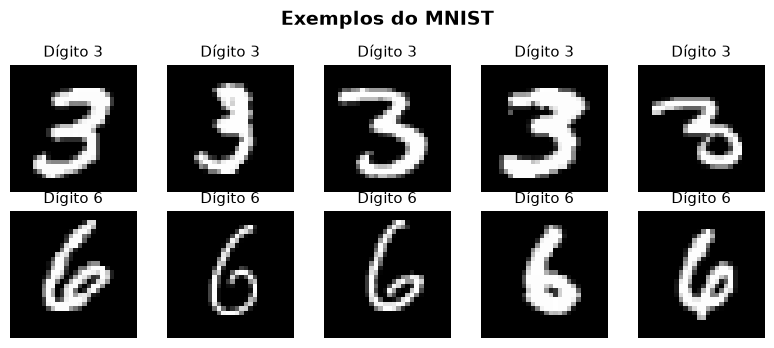

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))

for row, digit in enumerate(["3", "6"]):
    images = mnist.data[mnist.target == digit].iloc[:5].to_numpy()
    for axis, image in zip(axes[row], images):
        axis.imshow(image.reshape(28, 28), cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"Dígito {digit}", fontsize=11)
        axis.axis("off")

fig.suptitle("Exemplos do MNIST", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Visualização dos dados com t-SNE

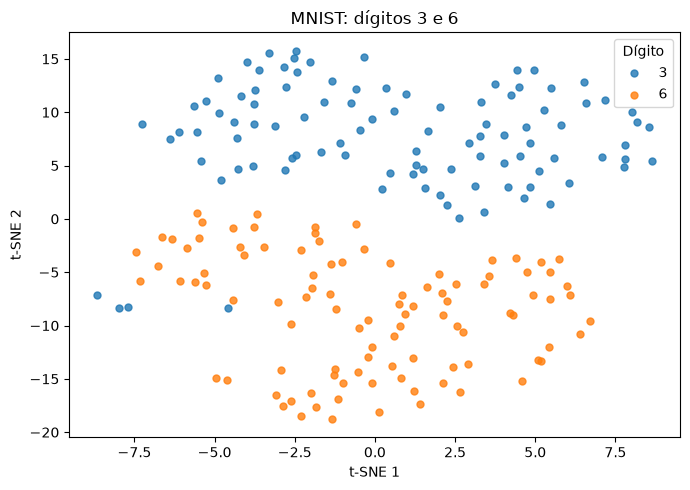

In [5]:
def visualize_dataset(X, labels):
    tsne = TSNE(n_components=2, random_state=42, perplexity=30)
    X_tsne = tsne.fit_transform(X)
    label_names = {0: "3", 1: "6"}

    plt.figure(figsize=(7, 5))
    for label in np.unique(labels):
        indices = labels == label
        plt.scatter(X_tsne[indices, 0], X_tsne[indices, 1], s=25, alpha=0.8, label=label_names[label])

    plt.title("MNIST: dígitos 3 e 6")
    plt.xlabel("t-SNE 1")
    plt.ylabel("t-SNE 2")
    plt.legend(title="Dígito")
    plt.tight_layout()
    plt.show()


visualize_dataset(X_train_sample, y_train_sample)

## Funções de avaliação

In [6]:
n_samples = list(range(10, n_sample_max + 10, 10))


def train_svm(C):
    model = SVC(kernel="linear", C=C)
    accuracy = []

    for n_sample in n_samples:
        selected_indices = np.concatenate([np.arange(n_sample), np.arange(n_sample_max, n_sample_max + n_sample)])
        model.fit(X_train_sample[selected_indices], y_train_sample[selected_indices])
        prediction = model.predict(X_test)
        accuracy.append(accuracy_score(y_test, prediction))

    print(f"Acurácia no teste: {accuracy[-1]:.2%}")
    print("Erros no treino:", np.count_nonzero(model.predict(X_train_sample) != y_train_sample))
    print("Vetores de suporte:", len(model.support_))
    return model, prediction, accuracy


def plot_accuracy(accuracy, title):
    plt.figure(figsize=(7, 4))
    plt.plot(n_samples, accuracy, marker="o", color="#2563eb")
    plt.title(title)
    plt.xlabel("Imagens de treino por dígito")
    plt.ylabel("Acurácia no teste")
    plt.xticks(n_samples)
    plt.ylim(0, 1)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

In [7]:
def plot_confusion(prediction, title):
    matrix = confusion_matrix(y_test, prediction, labels=[0, 1])
    percentages = matrix / matrix.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(5.5, 5), dpi=140)
    ax.imshow(matrix, cmap="Blues", vmin=0)

    for row in range(2):
        for column in range(2):
            color = "white" if matrix[row, column] > matrix.max() / 2 else "#17365d"
            ax.text(column, row, f"{matrix[row, column]}\n{percentages[row, column]:.1%}", ha="center", va="center", fontsize=18, fontweight="bold", color=color)

    ax.set_xticks([0, 1], ["3", "6"], fontsize=13)
    ax.set_yticks([0, 1], ["3", "6"], fontsize=13)
    ax.set_xlabel("Dígito previsto", fontsize=12, labelpad=10)
    ax.set_ylabel("Dígito real", fontsize=12, labelpad=10)
    ax.set_title(title, fontsize=15, fontweight="bold", pad=18)
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="white", linewidth=4)
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    fig.text(0.5, 0.025, "Quantidade de imagens e percentual por classe real", ha="center", fontsize=9, color="#475569")
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

## Margem suave

In [8]:
model, prediction, accuracy = train_svm(C=0.01)

Acurácia no teste: 97.22%
Erros no treino: 6
Vetores de suporte: 135


### Curva de acurácia — margem suave

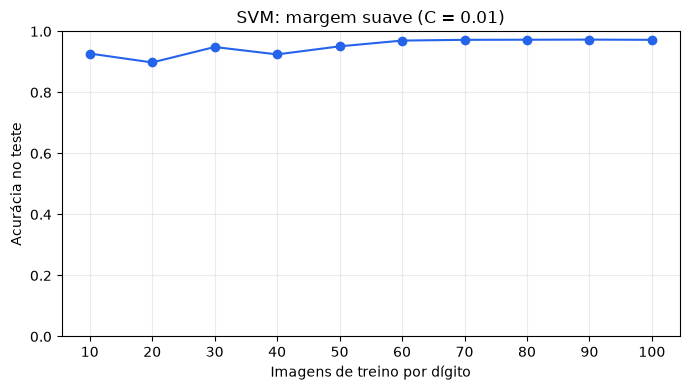

In [9]:
plot_accuracy(accuracy, "SVM: margem suave (C = 0.01)")

### Matriz de confusão — margem suave

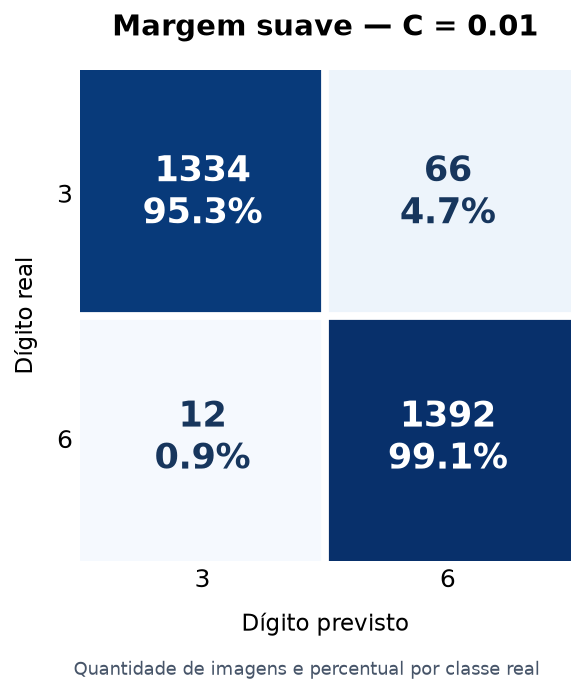

In [10]:
plot_confusion(prediction, "Margem suave — C = 0.01")

## Projeção dos dados e da solução

In [11]:
direction = PCA(n_components=1, random_state=42).fit(X_train_sample).components_[0]
projection, _ = np.linalg.qr(np.column_stack([model.coef_[0], direction]))
X_plot = X_train_sample @ projection
x_limits = (X_plot[:, 0].min() - 0.5, X_plot[:, 0].max() + 0.5)
y_limits = (X_plot[:, 1].min() - 0.5, X_plot[:, 1].max() + 0.5)
xx, yy = np.meshgrid(np.linspace(*x_limits, 250), np.linspace(*y_limits, 250))
grid = np.column_stack([xx.ravel(), yy.ravel()]) @ projection.T


def plot_solution(model, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)

    for axis in axes:
        for label, digit in [(0, "3"), (1, "6")]:
            indices = y_train_sample == label
            axis.scatter(X_plot[indices, 0], X_plot[indices, 1], s=25, alpha=0.8, label=digit)
        axis.set(xlim=x_limits, ylim=y_limits, xlabel="Projeção 1")

    decision = model.decision_function(grid).reshape(xx.shape)
    axes[1].contour(xx, yy, decision, levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"])
    support = X_plot[model.support_]
    axes[1].scatter(support[:, 0], support[:, 1], s=90, facecolors="none", edgecolors="black", label="Vetores de suporte")
    axes[0].set_title("Dados projetados")
    axes[1].set_title("Dados com a solução do SVM")
    axes[0].set_ylabel("Projeção 2")
    axes[0].legend(title="Dígito")
    axes[1].legend()
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()

### Dados e solução — margem suave

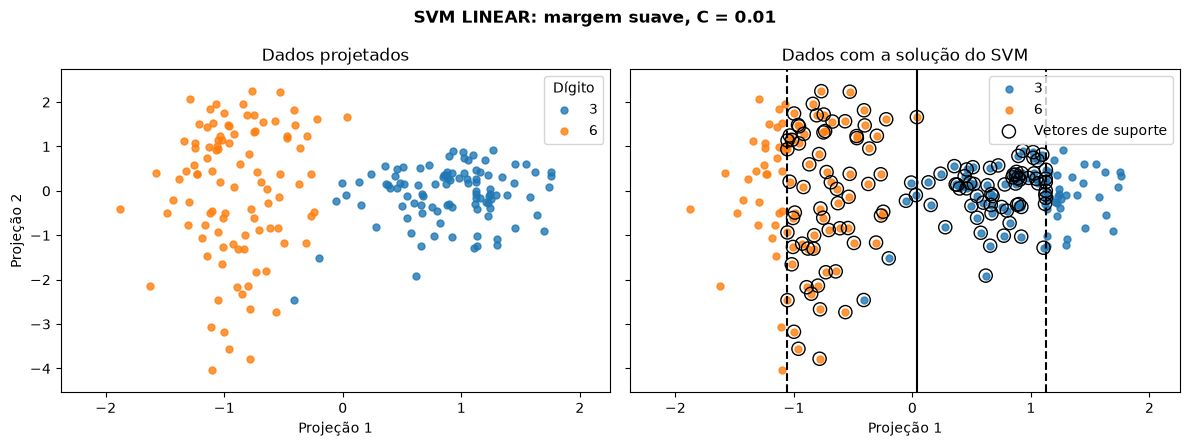

In [12]:
plot_solution(model, f"SVM {model.kernel.upper()}: margem suave, C = {model.C:g}")